# Dataset description
## Hectares of coca eradicated and dectection of cultivaded hectares of coca per year

Source: [MinDefensa](https://www.mindefensa.gov.co/defensa-y-seguridad/datos-y-cifras/informacion-estadistica) & [Ministerio de Justicia y derecho](https://www.datos.gov.co/Justicia-y-Derecho/Detecci-n-de-Cultivos-de-Coca-hect-reas-/acs4-3wgp/about_data)

# Code
## Imports

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Load data

In [42]:
path_err = "./data/erradicacion.csv"
path_dect = "./data/Detección_de_Cultivos_de_Coca_(hectáreas)_20261003.csv"

err_cols = [
    "FECHA_HECHO", "TIPO_CULTIVO", "CANTIDAD"
]
df_err = pd.read_csv(path_err, encoding="utf-8", usecols=err_cols)
df_dect = pd.read_csv(path_dect, encoding="utf-8")

## Clean data

In [43]:
df_dect.drop(columns=["CODDEPTO", "DEPARTAMENTO", "CODMPIO", "MUNICIPIO"], inplace=True)

df_dect["2020"] = df_dect["2020"].str.replace(",", "").astype(float)

total_dect = df_dect.sum()

In [44]:
df_err_f = df_err[df_err["TIPO_CULTIVO"].eq("COCA")].drop(columns=["TIPO_CULTIVO"])

df_err_f["FECHA_HECHO"] = pd.to_datetime(df_err_f["FECHA_HECHO"])
df_err_f["FECHA_HECHO"] = df_err_f["FECHA_HECHO"].dt.year

total_err = df_err_f.groupby("FECHA_HECHO").sum()

In [ ]:
total_dect.index.name = "FECHA_HECHO"
total_dect.name = "CANTIDAD_DECT"
total_dect.index = total_dect.index.astype(int)

total_err = total_err.squeeze()
total_err.name = "CANTIDAD_ERR"

total = pd.merge(total_dect, total_err, left_index=True, right_index=True, how="inner")

## Plot

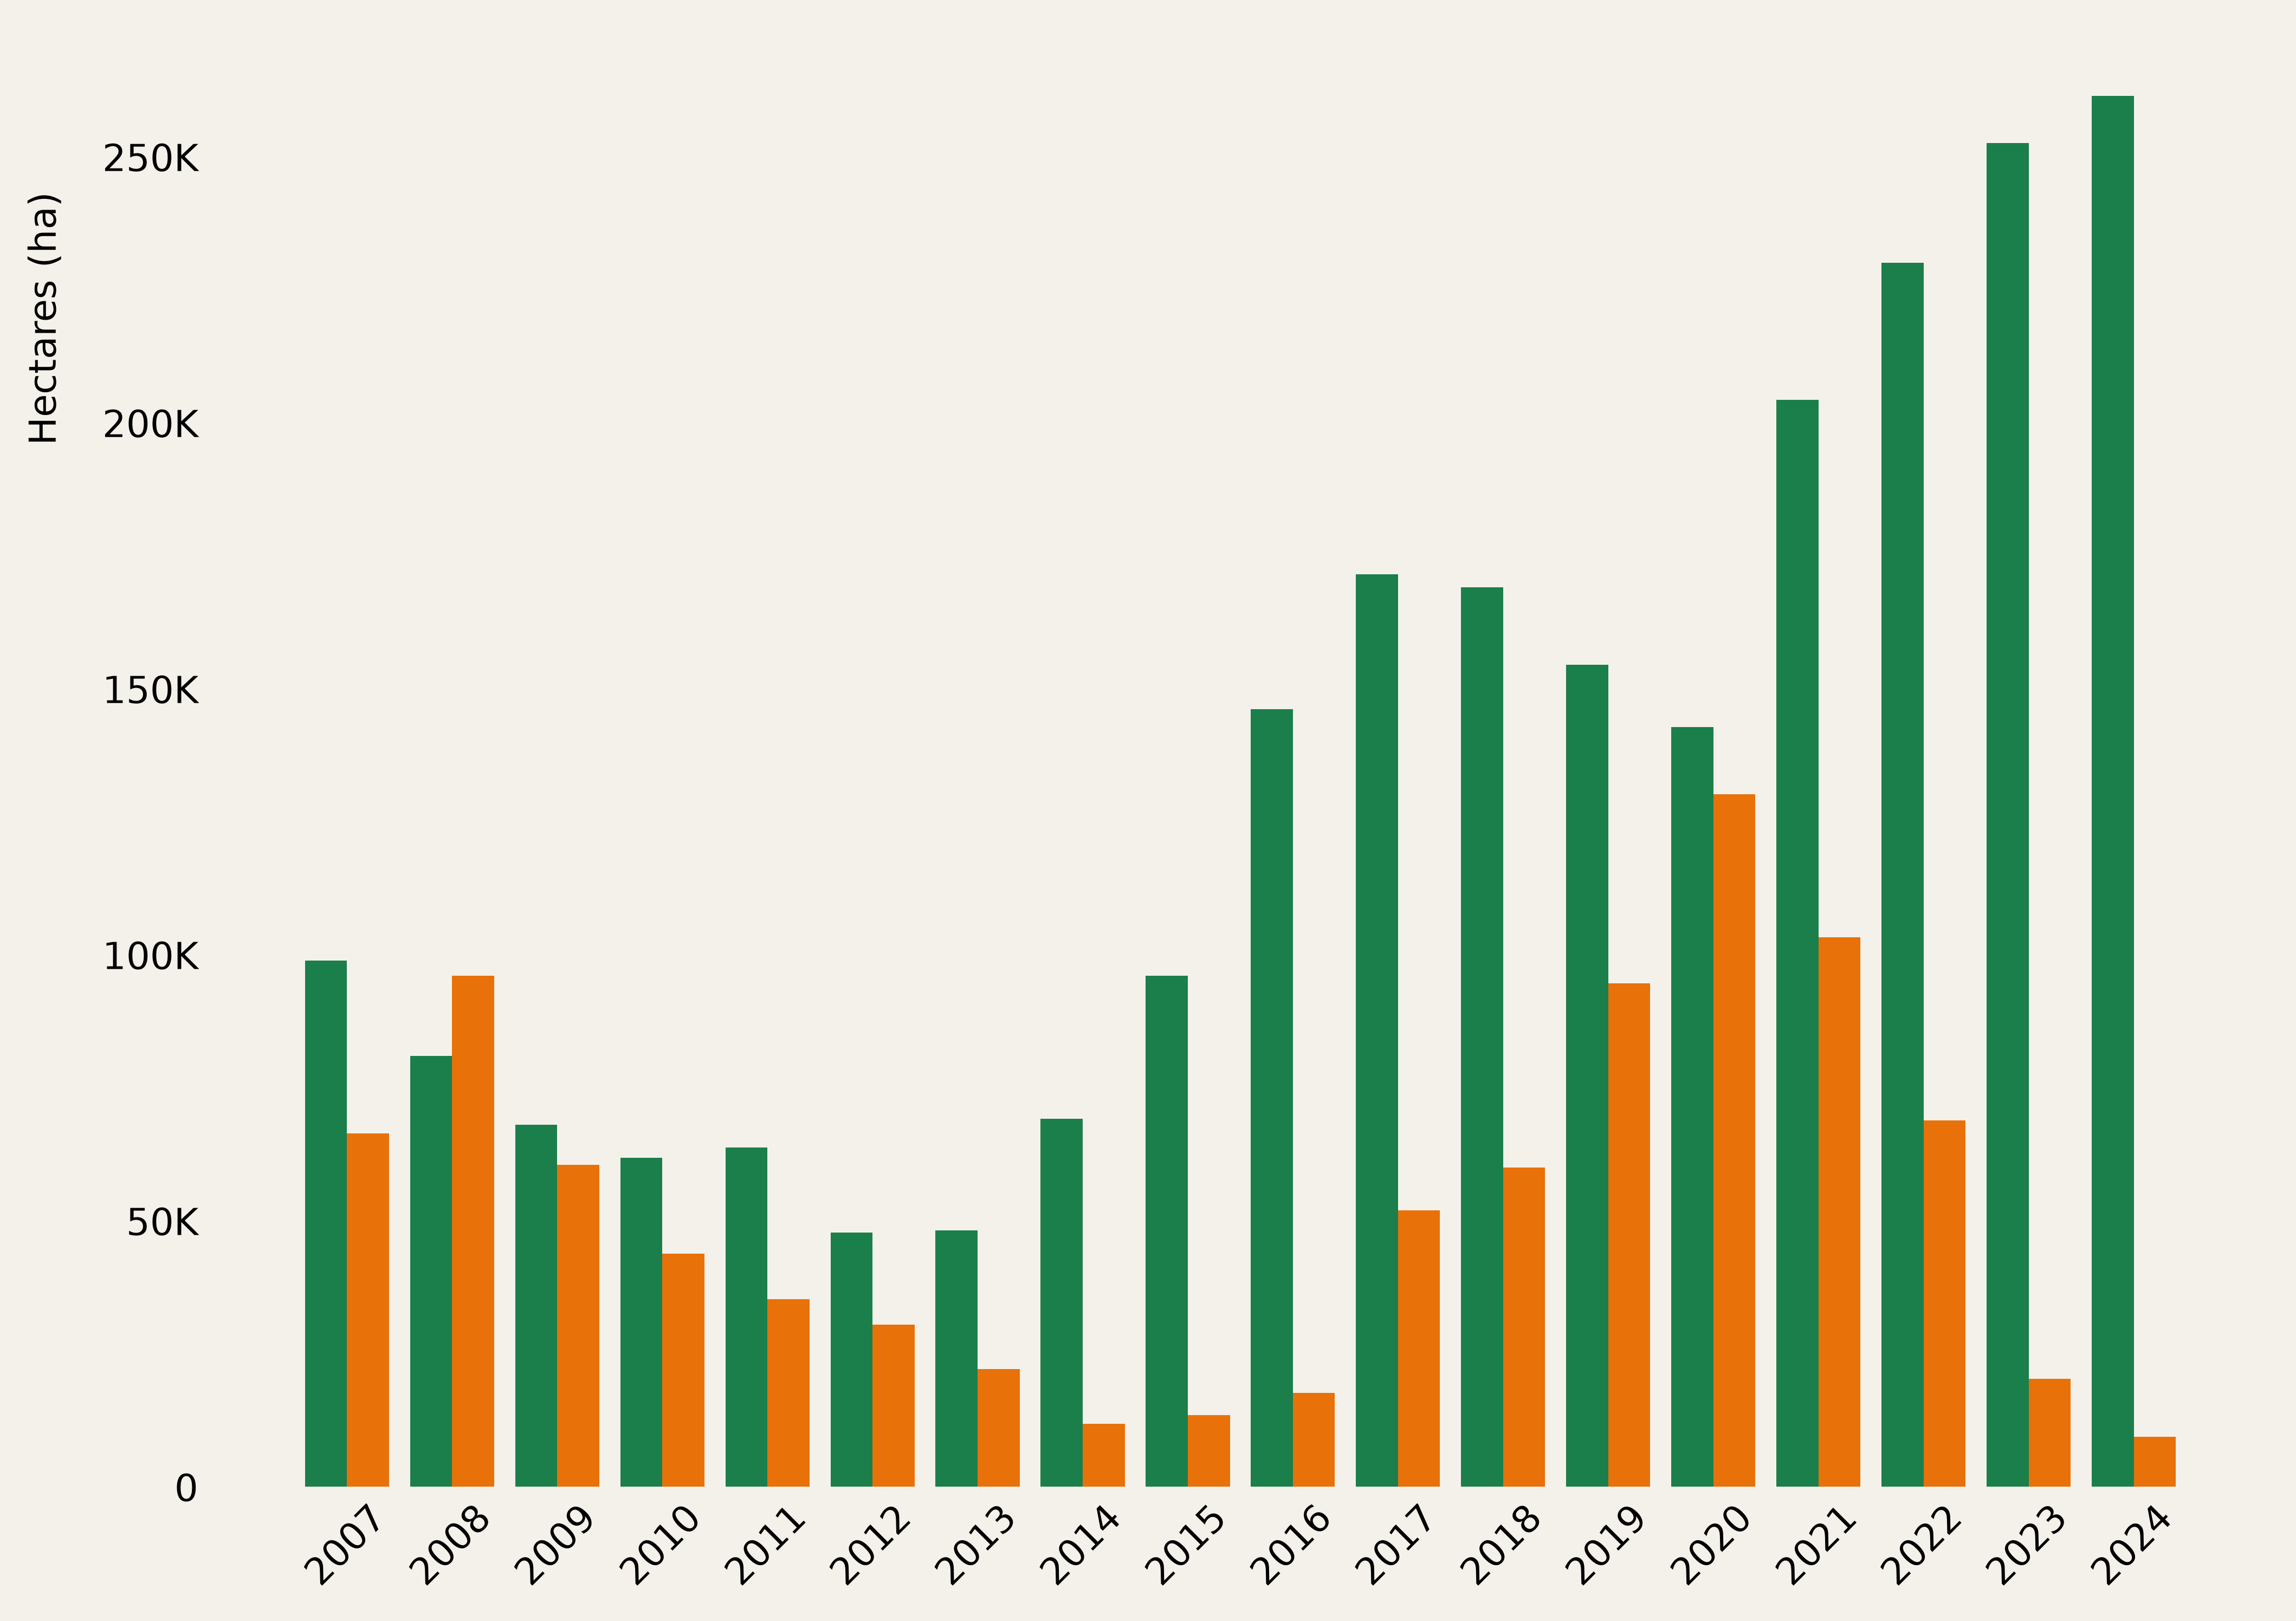

In [82]:
background = "#F4F1EA"
detected = "#1B7F4B"
eradicated = "#E8710A"

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

x_axis = np.array(range(len(total.index)))

width = 0.4

plt.bar([x - width/2 for x in x_axis], total["CANTIDAD_DECT"], width, color=detected)
plt.bar([x + width/2 for x in x_axis], total["CANTIDAD_ERR"], width, color=eradicated)

plt.xticks(ticks=x_axis, labels=total.index, rotation=45)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{int(x/1000)}K" if x != 0 else "0")
)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Hectares (ha)", labelpad=10, fontsize=10, y=0.8)

plt.show()